![Alt text](https://imgur.com/orZWHly.png=80)
source: @allison_horst https://github.com/allisonhorst/penguins

You have been asked to support a team of researchers who have been collecting data about penguins in Antartica! The data is available in csv-Format as `penguins.csv`

**Origin of this data** : Data were collected and made available by Dr. Kristen Gorman and the Palmer Station, Antarctica LTER, a member of the Long Term Ecological Research Network.

**The dataset consists of 5 columns.**

Column | Description
--- | ---
culmen_length_mm | culmen length (mm)
culmen_depth_mm | culmen depth (mm)
flipper_length_mm | flipper length (mm)
body_mass_g | body mass (g)
sex | penguin sex

Unfortunately, they have not been able to record the species of penguin, but they know that there are **at least three** species that are native to the region: **Adelie**, **Chinstrap**, and **Gentoo**.  Your task is to apply your data science skills to help them identify groups in the dataset!

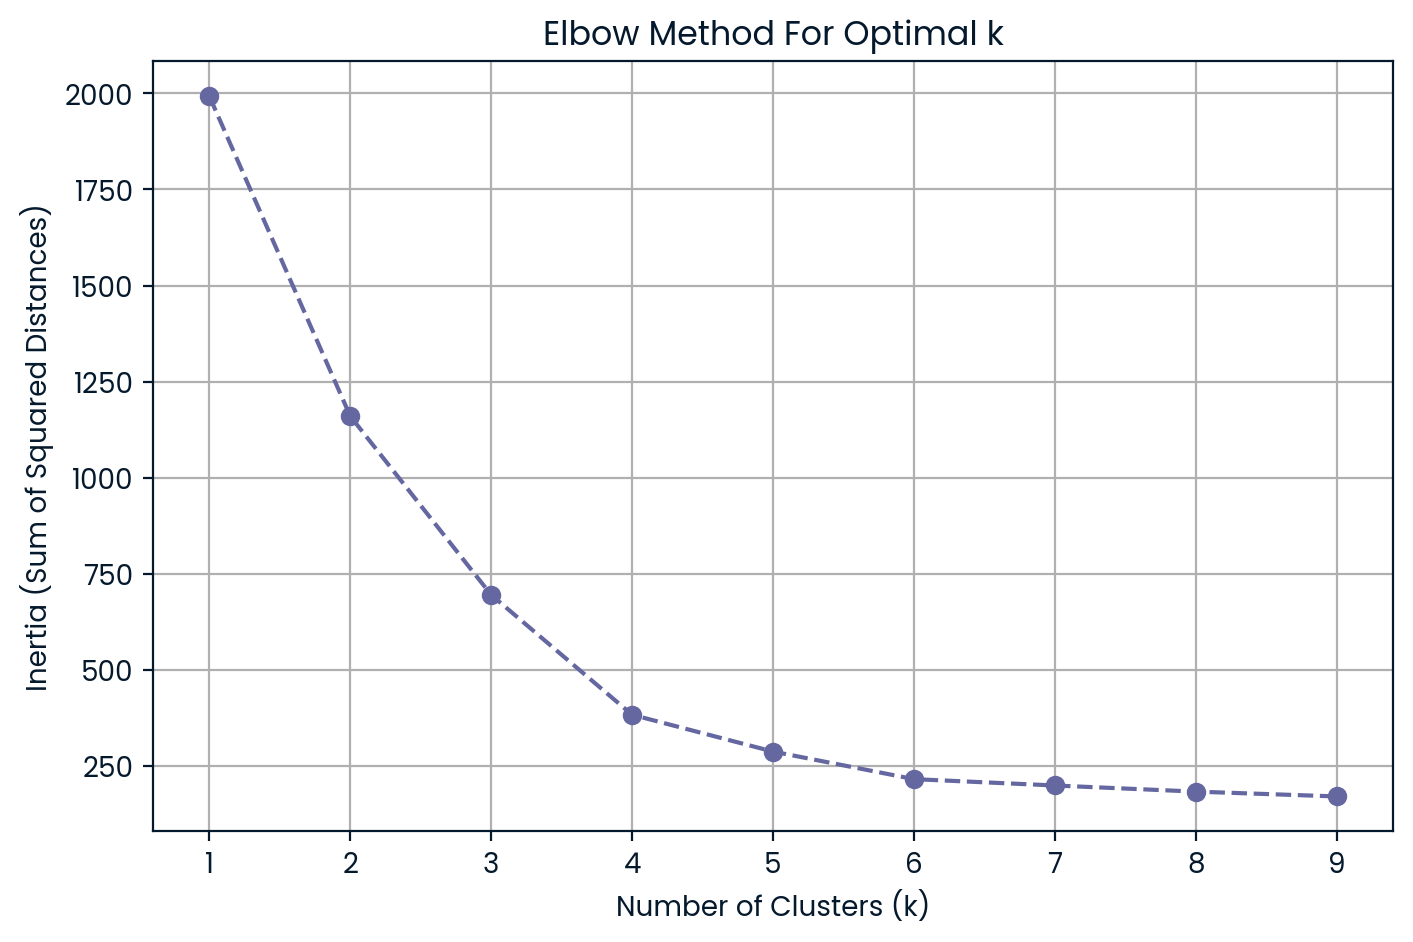

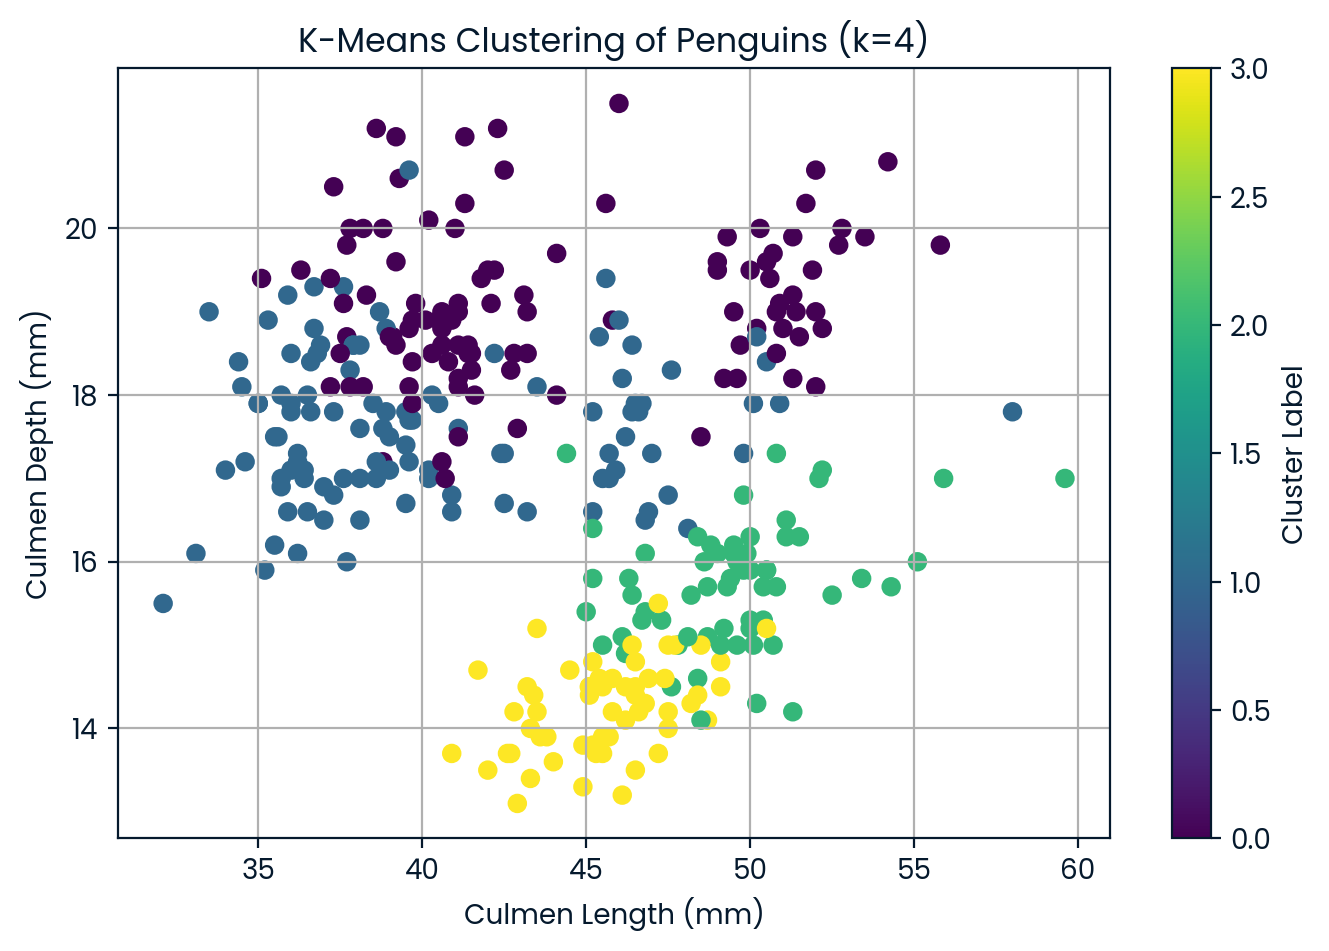

       culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
label                                                                   
0             43.878302        19.111321         194.764151  4006.603774
1             40.217757        17.611215         189.046729  3419.158879
2             49.473770        15.718033         221.540984  5484.836066
3             45.563793        14.237931         212.706897  4679.741379


In [2]:
# Import Required Packages
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Define the optimal number of clusters from your elbow graph
n_clusters = 4
# Create an empty list to store the inertia values
inertia_list = []
# Initialize the scaler
scaler = StandardScaler()
# Create a list of the numeric (non-binary) measurement columns
# (We exclude dummy variables like sex or island)
numeric_columns = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]
# Loading and examining the dataset
penguins_df = pd.read_csv("penguins.csv")
penguins_df.head()
# This automatically converts all string columns to numeric dummies AND drops the originals
penguins_processed = pd.get_dummies(penguins_df, dtype="int")

# Fit and scale your processed dataframe (with your dummy variables!)
penguins_scaled = scaler.fit_transform(penguins_processed)
# Loop through cluster ranges from 1 to 9 inclusive
for k in range(1,10):
    # Initialize KMeans with the current cluster number and random_state 42
    kmeans = KMeans(n_clusters=k, random_state=42)
    
    # Fit the model onto your scaled data
    kmeans.fit(penguins_scaled)

    # Access the inertia value and append it to the list
    inertia_list.append(kmeans.inertia_)
    
# Plot the Elbow Curve to visualize the inflection point
plt.figure(figsize=(8, 5))
plt.plot(range(1, 10), inertia_list, marker="o", linestyle="--")
plt.title("Elbow Method For Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Sum of Squared Distances)")
plt.xticks(range(1, 10))
plt.grid(True)
plt.show()

# Initialize and fit the KMeans model on your preprocessed data
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(penguins_scaled)

# Create cluster labels and assign them to your DataFrame
penguins_df["label"] = kmeans.labels_

# Visualize the defined clusters using a scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(
    x=penguins_df["culmen_length_mm"],
    y=penguins_df["culmen_depth_mm"],
    c=penguins_df["label"],
    cmap="viridis",
)

plt.title(f"K-Means Clustering of Penguins (k={n_clusters})")
plt.xlabel("Culmen Length (mm)")
plt.ylabel("Culmen Depth (mm)")
plt.colorbar(label="Cluster Label")
plt.grid(True)
plt.show()
# Create the final characteristic DataFrame by grouping and getting the mean
stat_penguins = penguins_df.groupby("label")[numeric_columns].mean()

# Display the final summary table
print(stat_penguins)